Here I created embedding on collab GPU, no need to run this cell, I already sent it to you on email. Everything that we need needs to be in data/artifacts.


Note: I appended title with the paragraph for embedding to gain a bit of context

In [ ]:
# import os
# import json
# import numpy as np
# import pandas as pd
# from sentence_transformers import SentenceTransformer

# # 1. POINT EXPLICITLY TO YOUR UPLOADED FILE LOCATIONS
# # Change your paths to this:
# NODES_PATH = "/content/nodes.parquet"       
# QUESTIONS_PATH = "/content/questions.parquet"

# print("Reading data tables out of /content/rl/...")
# docs_df = pd.read_parquet(NODES_PATH)
# queries_df = pd.read_parquet(QUESTIONS_PATH)
# print(f"Loaded {len(docs_df)} documents and {len(queries_df)} queries successfully!")

# # Format your text column like this before running encode_texts:
# docs_df["title_text"] = docs_df["title"] + " - " + docs_df["text"]

# # 2. EMBEDDING ENGINE SETUP
# def _freeze_hash(df):
#     # Deterministic contract hash to tie embeddings to this exact corpus snapshot
#     return str(hash(tuple(df["node_id"].tolist())))

# def encode_texts(model, texts, batch_size=256, instruction=None):
#     if instruction:
#         texts = [instruction + t for t in texts]
#     emb = model.encode(
#         texts, 
#         batch_size=batch_size, 
#         normalize_embeddings=True, # Allows downstream fast dot-product instead of full cosine math
#         show_progress_bar=True, 
#         convert_to_numpy=True
#     )
#     return np.ascontiguousarray(emb, dtype=np.float32)

# # Load the model directly into Colab's active CUDA GPU hardware
# print("\nInitializing BGE Model on Cloud GPU...")
# model = SentenceTransformer("BAAI/bge-base-en-v1.5", device="cuda")

# print("Encoding master corpus documents...")
# doc_emb = encode_texts(model, docs_df["title_text"].tolist())

# print("Encoding queries...")
# query_emb = encode_texts(
#     model, 
#     queries_df["query_text"].tolist(), 
#     instruction="Represent this sentence for searching relevant passages: "
# )

# query_ids = queries_df["question_id"].to_numpy().astype(str)

# manifest = dict(
#     model_name="BAAI/bge-base-en-v1.5", 
#     dim=int(doc_emb.shape[1]), 
#     n_docs=int(doc_emb.shape[0]),
#     n_queries=int(query_emb.shape[0]), 
#     normalized=True, 
#     query_instruction="Represent this sentence for searching relevant passages: ",
#     corpus_node_id_hash=_freeze_hash(docs_df)
# )

# # 3. WRITE ARTIFACTS TEMPORARILY TO THE CLOUD DRIVE
# print("\nWriting generated matrices to temporary cloud storage...")
# OUTPUT_DIR = "/content/rl/artifacts"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# np.save(f"{OUTPUT_DIR}/doc_emb.npy", doc_emb)
# np.save(f"{OUTPUT_DIR}/query_emb.npy", query_emb)
# np.save(f"{OUTPUT_DIR}/query_ids.npy", query_ids)

# with open(f"{OUTPUT_DIR}/embeddings_manifest.json", "w") as f:
#     json.dump(manifest, f, indent=2)

# print(f"🎉 Matrix compilation complete! Vectors saved to: {OUTPUT_DIR}")

Reading data tables out of /content/rl/...
Loaded 101962 documents and 22355 queries successfully!

Initializing BGE Model on Cloud GPU...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

...

Encoding master corpus documents...


Batches:   0%|          | 0/399 [00:00<?, ?it/s]

Encoding queries...


Batches:   0%|          | 0/88 [00:00<?, ?it/s]


Writing generated matrices to temporary cloud storage...
🎉 Matrix compilation complete! Vectors saved to: /content/rl/artifacts


# a little bit of EDA for embeddings

In [5]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. LOAD THE DATA AND FRESHLY GENERATED EMBEDDING ARTIFACTS
ARTIFACTS_DIR = "../data/artifacts"
NODES_PATH = "../data/interim/nodes.parquet"       
QUESTIONS_PATH = "../data/interim/questions.parquet"

docs_df = pd.read_parquet(NODES_PATH)
queries_df = pd.read_parquet(QUESTIONS_PATH)

doc_emb = np.load(f"{ARTIFACTS_DIR}/doc_emb.npy")
query_emb = np.load(f"{ARTIFACTS_DIR}/query_emb.npy")
query_ids = np.load(f"{ARTIFACTS_DIR}/query_ids.npy")

In [7]:
doc_emb.shape

(101962, 768)

In [8]:
query_emb.shape

(22355, 768)

In [10]:
query_ids.shape

(22355,)

In [12]:
queries_df.head(1)

,question_id,split,query_text,n_hops,gold_node_ids,candidate_node_ids,answer
0,3hop1__614774_42467_91253,train,What is the period of revolution of the planet...,3,"[19, 11, 7]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",88 days


Analyzing dense vector similarities across candidate pools...


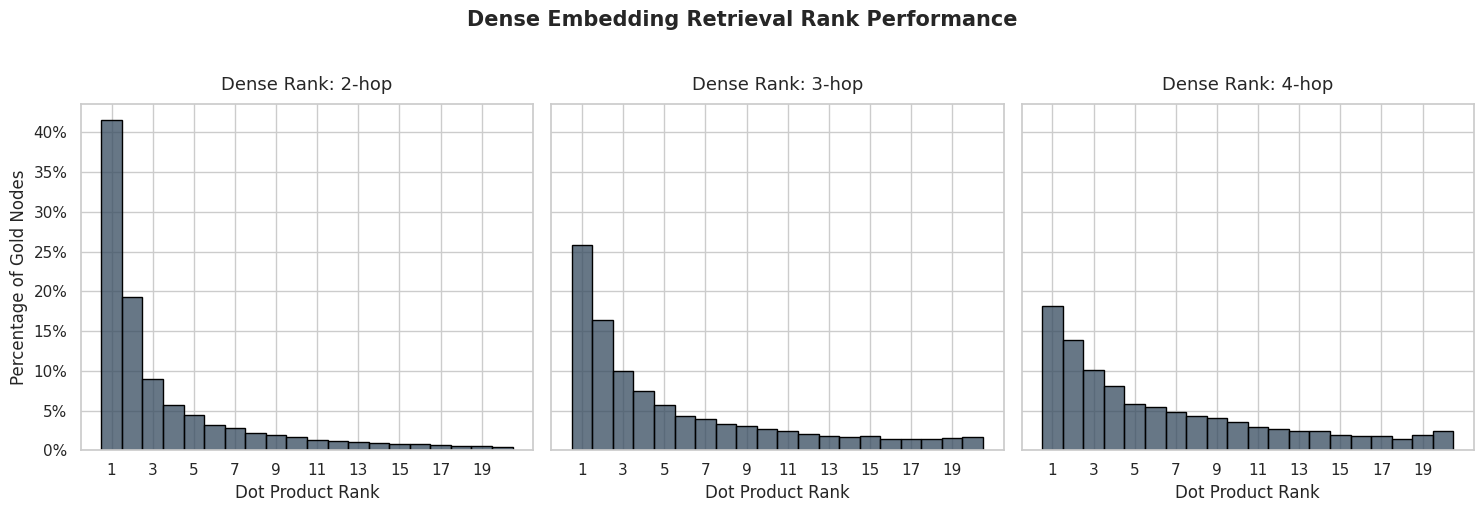

In [17]:
# Create lookup mappings
node_id_to_idx = {node_id: idx for idx, node_id in enumerate(docs_df["node_id"])}
query_id_to_idx = {qid: idx for idx, qid in enumerate(query_ids)}

# ---------------------------------------------------------------------------
# DIAGNOSTIC 1: COMPUTE RANKS PER N-HOP CATEGORY
# ---------------------------------------------------------------------------
ranks_records = []
gold_scores = []
distractor_scores = []

print("Analyzing dense vector similarities across candidate pools...")
for _, row in queries_df.iterrows():
    q_id = str(row["question_id"])
    if q_id not in query_id_to_idx:
        continue
        
    n_hops = row["n_hops"]
    gold_ids = set(row["gold_node_ids"])
    candidate_ids = row["candidate_node_ids"]
    
    # Extract the pre-computed query vector
    q_idx = query_id_to_idx[q_id]
    v_query = query_emb[q_idx] # Shape: (768,)
    
    # Gather matching cloud indices for the candidates
    cand_matrix_indices = [node_id_to_idx[cid] for cid in candidate_ids if cid in node_id_to_idx]
    if not cand_matrix_indices:
        continue
        
    # Extract candidate document vectors
    v_candidates = doc_emb[cand_matrix_indices] # Shape: (N_candidates, 768)
    
    # MATHEMATICAL WIN: Because your vectors are unit-normalized to length 1,
    # Cosine Similarity is calculated instantly via a basic matrix-vector Dot Product!
    sim_scores = np.dot(v_candidates, v_query) 
    
    # Map candidate IDs to their dot-product similarity score
    cand_to_score = {cid: score for cid, score in zip(candidate_ids, sim_scores)}
    
    # Store scores for Gold vs Distractor analysis
    for cid, score in zip(candidate_ids, sim_scores):
        if cid in gold_ids:
            gold_scores.append(score)
        else:
            distractor_scores.append(score)
            
    # Calculate exact dense ranks for each gold answer node
    for gold_id in gold_ids:
        if gold_id in cand_to_score:
            gold_score = cand_to_score[gold_id]
            # Rank = 1 + how many candidates beat the gold score
            rank = np.sum(sim_scores > gold_score) + 1
            ranks_records.append({"n_hops": n_hops, "rank": rank})

ranks_df = pd.DataFrame(ranks_records)

# ---------------------------------------------------------------------------
# PLOT 1: SIDE-BY-SIDE N-HOP RANK HISTOGRAMS (WITH PERCENTAGES)
# ---------------------------------------------------------------------------
sns.set_theme(style="whitegrid")
hop_groups = sorted(ranks_df["n_hops"].unique())

fig, axes = plt.subplots(1, len(hop_groups), figsize=(5 * len(hop_groups), 5), sharey=True)
if len(hop_groups) == 1:
    axes = [axes]

for ax, hop in zip(axes, hop_groups):
    subset = ranks_df[ranks_df["n_hops"] == hop]
    
    sns.histplot(
        data=subset, 
        x="rank", 
        bins=np.arange(0.5, 21.5, 1),
        stat="percent", # 👈 Changes the calculation from absolute Count to Percentage
        ax=ax, 
        kde=False, 
        color="#34495e", 
        edgecolor="black"
    )
    
    ax.set_title(f"Dense Rank: {hop}-hop", fontsize=13, pad=10)
    ax.set_xlabel("Dot Product Rank")
    ax.set_xticks(range(1, 21, 2))
    
    # Format the y-tick labels dynamically to append a '%' sign
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0f}%'))

# Adjust the shared y-axis label on the leftmost plot to reflect the change
axes[0].set_ylabel("Percentage of Gold Nodes", fontsize=12)

plt.suptitle("Dense Embedding Retrieval Rank Performance", y=1.02, fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

roughly in 50% of the cases the cos similarity does not cut it

<>:14: SyntaxWarning: invalid escape sequence '\l'
<>:14: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_7908/2984084442.py:14: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel("Vector Dot Product $\langle e_{d}, e_q \\rangle$", fontsize=12)


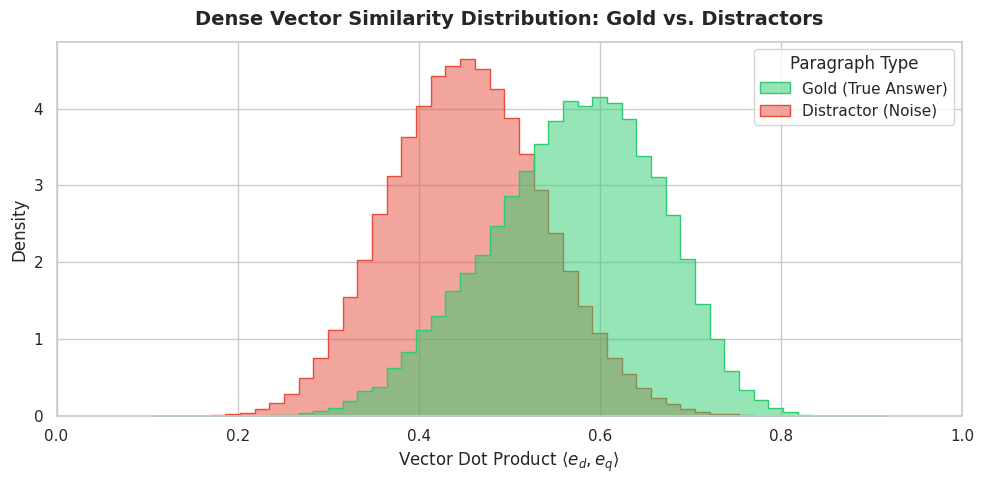

In [16]:
# ---------------------------------------------------------------------------
# PLOT 2: OVERLAPPING DENSITY (GOLD VS. DISTRACTORS)
# ---------------------------------------------------------------------------
df_gold = pd.DataFrame({"Similarity": gold_scores, "Paragraph Type": "Gold (True Answer)"})
df_dist = pd.DataFrame({"Similarity": distractor_scores, "Paragraph Type": "Distractor (Noise)"})
plot_df = pd.concat([df_gold, df_dist], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=plot_df, x="Similarity", hue="Paragraph Type", element="step", stat="density",
    common_norm=False, bins=50, palette={"Gold (True Answer)": "#2ecc71", "Distractor (Noise)": "#e74c3c"}, alpha=0.5
)
plt.title("Dense Vector Similarity Distribution: Gold vs. Distractors", fontsize=14, pad=12, weight='bold')
plt.xlabel("Vector Dot Product $\langle e_{d}, e_q \\rangle$", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.xlim(0, 1.0) # Showing full theoretical range of dot products
plt.tight_layout()
plt.show()